---   
 <img align="left" width="75" height="75"  src="https://upload.wikimedia.org/wikipedia/en/c/c8/University_of_the_Punjab_logo.png"> 

<h1 align="center">Department of Data Science</h1>

---
<h3><div align="right">Instructor: Muhammad Arif Butt, Ph.D.</div></h3>    

<br><br>
<h1 align="center">Lec-30: Overview of LangChain and its <b>Models</b> Component</h1>

# Learning agenda of this notebook

> **The idea of this lecture:** this is our first lecture on a **framework**. Every model provider has its own SDK, with its own way to call a model and read the answer. **LangChain** puts one standard interface in front of all of them, so we learn it once and use it with OpenAI, Claude, Gemini, Groq, OpenRouter and Ollama. Today we study its first building block, the **Models** component; the next eight lectures add the others, one at a time.

1. **Why LangChain?**
    - The problem: one SDK per provider. The fix: one interface for all of them
2. **LangChain Today**
    - LLM frameworks at a glance
    - The LangChain family of packages, and the road ahead (Lec-30 to 38, then agents)
3. **The Models Component**
    - Chat models, text-completion models and embedding models; base and instruction-tuned models
    - Setup: versions and API keys
4. **Closed-Source Chat Models**
    - Example 1: OpenAI, Claude and Gemini, each with its own LangChain class
    - Example 2: `init_chat_model()`: switching provider by changing one string
5. **Open-Source Chat Models**
    - Example 3: Groq, through an OpenAI-compatible URL
    - Example 4: OpenRouter: free models, the empty-reply trap and a fallback list
    - Example 5: Ollama, on your own laptop
6. **Working with a Chat Model**
    - Example 6: Anatomy of one call: messages in, an `AIMessage` out
    - Example 7: A conversation by hand: the model remembers nothing
    - Example 8: `invoke()`, `stream()` and `batch()`
    - Example 9: Structured output: a Python object instead of text
7. **Images In and Out**
    - Example 10: Image in: the same message to two providers
    - Example 11: Image out: OpenAI's image tool, and a local model
8. **Hands-On Practice**
    - Question answering, classification, generation, translation, summarisation, entity extraction, and a batch of reviews
9. **Embedding Models**
    - Example 12: A closed-source embedding model (OpenAI)
    - Example 13: An open-source embedding model through an API (OpenRouter, free)
    - Example 14: An open-source embedding model on your laptop (Hugging Face)
10. **Summary: From Provider SDKs → LangChain**

> **Note on cost:** almost everything runs on **free** models: Groq's free tier (`gpt-oss-120b`, `gpt-oss-20b`, `qwen3.8-27b`), OpenRouter's `:free` models, Gemini's free tier, and Ollama and Hugging Face models on your laptop. Paid models are called **once each**, only where nothing free can do the job: `gpt-4o-mini` and `claude-haiku-5-5` (Example 1), `gpt-image-1-mini` (Example 11) and `text-embedding-3-small` (Example 12). The whole notebook costs a few US cents at most.

# <span style='background :lightgreen' >1. Why LangChain?</span>

## The problem: one SDK per provider
- Every provider ships its **own SDK**: a different import, a different way to create a client, a different method to call the model, and a different place to find the answer in the response.
- An app that uses two providers needs two sets of code. **Switching** provider means rewriting the calls and the parsing; trying five models means learning five SDKs.
- On top of the model calls, every LLM app needs the same pieces again and again: prompt templates, conversation history, document loading, search, chaining steps together, and later agents.

## The fix: one interface for all of them
**LangChain** is an open-source framework that gives every provider the **same interface**: `model.invoke(messages)` returns an `AIMessage`, whatever model is behind it. Small **integration packages** (`langchain-openai`, `langchain-anthropic`, …) translate each call into the provider's own API. On top of that interface, LangChain adds the other building blocks of an LLM app, which we study in Lec-31 to 38.

<div style="text-align:center;">
    <img src="../images/langchain-new-01.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

# <span style='background :lightgreen' >2. LangChain Today</span>

## a. LLM frameworks at a glance
LangChain is not the only framework. The table lists the best-known ones, with their first release on PyPI (checked in November 2026). We use **LangChain** for Lec-30 to 38, write agents **from scratch** in Lec-39 to 50, and come back to frameworks in Lec-51 to 53.

| Framework | Icon | Type | First release | What it is | Best for |
|---|---|---|---|---|---|
| **[LangChain](https://www.langchain.com/langchain)** | <img src="../images/langchain-color.png" width="50"> | LLM app framework | Oct 2022 | The most widely used open-source framework for LLM apps: one interface for models, prompts, retrievers and tools. Since version 1.0 (Oct 2025) it also builds agents with `create_agent()` | LLM apps, RAG, quick agents with any provider (Lec-30 to 38, 51, 52) |
| **[LlamaIndex](https://www.llamaindex.ai/)** | <img src="../images/llamaindex-color.png" width="50"> | LLM app framework | Nov 2022 (as GPT Index) | A data framework that connects LLMs to your documents: loading, indexing and retrieval | Document question answering, RAG-heavy apps |
| **[Haystack](https://haystack.deepset.ai/)** | <img src="https://haystack.deepset.ai/images/logos/haystack.png" width="90"> | LLM app framework | Nov 2019 | deepset's framework for production search and RAG pipelines | Enterprise search |
| **[LangGraph](https://www.langchain.com/langgraph)** | <img src="../images/langgraph.png" width="50"> | Agent framework | Jan 2024 | The engine under LangChain's agents: steps as a graph, saved state, human approval | Custom multi-step and multi-agent workflows |
| **[CrewAI](https://www.crewai.com/)** | <img src="../images/crewai-color.png" width="50"> | Agent framework | Nov 2023 | Teams ("crews") of agents, each with a role, a goal and a backstory | Role-based multi-agent tasks |
| **[Microsoft Agent Framework](https://github.com/microsoft/agent-framework)** | <img src="../images/autogen-icon.png" width="90"> | Agent framework | Oct 2025 (1.0 in Apr 2026) | The successor of **AutoGen** (2023, now in maintenance mode) and Semantic Kernel: multi-agent orchestration for Python and .NET | Enterprise agents, the Microsoft/Azure ecosystem |
| **[OpenAI Agents SDK](https://github.com/openai/openai-agents-python)** | <img src="../images/agents-sdk-icon.png" width="90"> | Agent framework | Mar 2025 | A small library with three ideas: agents, handoffs and guardrails | Agents built mainly on OpenAI models (Lec-53) |
| **[Google ADK](https://google.github.io/adk-docs/)** | | Agent framework | Mar 2025 | Google's Agent Development Kit: multi-agent systems, made for Gemini but open to other models | Agents in the Google Cloud ecosystem |
| **[Claude Agent SDK](https://docs.claude.com/en/api/agent-sdk/overview)** | | Agent framework | Sep 2025 | The harness of Claude Code as a library: files, shell, sub-agents and skills | Long-running agents built on Claude |
| **[n8n](https://n8n.io/)** | <img src="../images/n8n.png" width="50"> | Workflow automation | 2019 | A visual, low-code tool that connects apps and AI models with drag-and-drop workflows | Automation without much code |

## b. The LangChain family of packages
- LangChain is not one library but a **family of small packages**. `langchain-core` holds the standard interfaces; one **integration package** per provider implements them; `langchain`, `langgraph` and `deepagents` build agents on top.
- The old **chains** and **memory** classes of LangChain 0.x were moved to `langchain-classic` in version 1.0. Many tutorials on the web still use them.
- This notebook needs `langchain`, `langchain-openai`, `langchain-anthropic`, `langchain-google-genai`, `langchain-openrouter`, `langchain-ollama` and `langchain-huggingface`, all in the course environment (`uv sync`).

<div style="text-align:center;">
    <img src="../images/langchain-new-02.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

## c. The road ahead
A question-answering app over your own documents (**RAG**) uses every building block of Lec-30 to 38. Today we study the two **models** in it: the **chat model** that writes the answer, and the **embedding model** that makes search by meaning possible.

<div style="text-align:center;">
    <img src="../images/langchain-new-03.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

> **Documentation:** https://docs.langchain.com/oss/python/langchain/overview · Models: https://docs.langchain.com/oss/python/langchain/models

# <span style='background :lightgreen' >3. The Models Component</span>

## a. Three kinds of models
LangChain has a standard interface for each kind of model. They differ in what goes **in** and what comes **out**:

<div style="text-align:center;">
    <img src="../images/langchain-new-04.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

## b. Base models and instruction-tuned (chat) models
A chat model starts life as a **base model** and is then taught to follow instructions.

| | **Base model** (completion) | **Instruction-tuned model** (chat) |
|---|---|---|
| **Training** | Next-token prediction on huge amounts of raw text | The base model + fine-tuning on instruction/answer pairs + preference training (RLHF) |
| **Input** | A piece of text to continue | A conversation with roles: system, user, assistant |
| **Behaviour** | Continues the text, in whatever direction the text suggests | Answers the question and follows the instructions |
| **Examples** | Open-weight base models such as Llama 3.1 8B or Mistral 7B (base) | `gpt-4o-mini`, `claude-haiku-5-5`, `gemini-3.5-flash-lite`, `gpt-oss-120b`, `qwen3.8-27b`, Llama 3.3 70B Instruct |
| **Used for** | Research, and as the starting point for your own fine-tuning (Lec-24 to 26) | Chat bots, assistants, RAG and agents: everything in this course |

Closed-source providers now offer almost only chat models, which is why LangChain's chat-model interface is the one we use.

## c. Setup: versions and API keys
- We load `../keys/.env` and print only **whether** each key is set, never any part of it.
- LangChain's provider classes read their key from the environment by themselves: `OPENAI_API_KEY`, `ANTHROPIC_API_KEY`, `GOOGLE_API_KEY` and `OPENROUTER_API_KEY`. Groq is reached through an OpenAI-compatible URL, so we pass `GROQ_API_KEY` ourselves (Example 3).

In [1]:
import os                                                   # read environment variables (the API keys)
from importlib.metadata import version                      # the installed version of a package, without importing it
from dotenv import load_dotenv                              # load the API keys from ../keys/.env

for package in ["langchain", "langchain-core", "langchain-openai", "langchain-anthropic", "langchain-google-genai",
                "langchain-openrouter", "langchain-ollama", "langchain-huggingface"]:   # the packages of this notebook
    print(f"{package:23}", version(package))                # :23 pads the name so the versions line up

load_dotenv("../keys/.env", override=True)                  # put the keys from the file into os.environ (the file wins)
print()
for key in ["OPENAI_API_KEY", "ANTHROPIC_API_KEY", "GOOGLE_API_KEY", "GROQ_API_KEY", "OPENROUTER_API_KEY"]:
    print(f"{key:19}", "set" if os.getenv(key) else "MISSING")   # never print any part of a key

langchain               1.4.7
langchain-core          1.7.3
langchain-openai        1.2.1
langchain-anthropic     1.7.7
langchain-google-genai  4.4.2
langchain-openrouter    0.2.9
langchain-ollama        1.1.0
langchain-huggingface   1.2.2

OPENAI_API_KEY      set
ANTHROPIC_API_KEY   set
GOOGLE_API_KEY      set
GROQ_API_KEY        set
OPENROUTER_API_KEY  set


# <span style='background :lightgreen' >4. Closed-Source Chat Models</span>

There are three ways to create a chat model in LangChain. All three give an object with the same methods:

<div style="text-align:center;">
    <img src="../images/langchain-new-05.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

## <span style='color:#7e22ce'>Example 1: OpenAI, Claude and Gemini, each with its own LangChain class</span>
- One class per provider, each from its own integration package. The **call** (`invoke`) and the **answer** (`.text`) are the same for all three.
- The two paid models are called only here. Gemini 3.5 Flash-Lite is on Google's free tier.
- Claude models no longer accept `temperature` (the current Anthropic API version, 2026-10-21, rejects it), and Gemini 3.5 ignores it (it uses fixed sampling settings), so we set it only for OpenAI.

In [2]:
from langchain_openai import ChatOpenAI                     # LangChain class for OpenAI models
from langchain_anthropic import ChatAnthropic               # LangChain class for Anthropic's Claude models
from langchain_google_genai import ChatGoogleGenerativeAI   # LangChain class for Google's Gemini models

models = {                                                  # each class reads its own key from the environment
    "OpenAI gpt-4o-mini":            ChatOpenAI(model="gpt-4o-mini", temperature=0.7, max_tokens=200),
    "Anthropic claude-haiku-5-5":    ChatAnthropic(model="claude-haiku-5-5", max_tokens=200),   # no temperature for Claude
    "Google gemini-3.5-flash-lite":  ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", max_tokens=200),   # no temperature for Gemini 3.5
}

for name, model in models.items():                          # the same two lines for every provider
    reply = model.invoke("Tell me a one-line joke about Generative AI")   # one call to the model
    print(f"\033[1m=== {name} ===\033[0m")                  # \033[1m ... \033[0m: print in bold
    print(reply.text, "\n")                                 # .text: the text of the answer, for every provider

=== OpenAI gpt-4o-mini ===
Why did the generative AI break up with its partner? Because it found too many "toxic prompts"! 

=== Anthropic claude-haiku-5-5 ===
Why did the generative AI break up with its partner? It found someone with more *depth* to their training data, but kept hallucinating that they still loved each other.

Hmm, that's a bit of a mouthful. Here's a tighter one:

Why did the generative AI get bad grades? It kept making things up and calling it "research." 

=== Google gemini-3.5-flash-lite ===
Generative AI is a lot like a confident intern who has read the entire internet, has no idea what’s actually true, and can generate 10,000 words on the history of paperclips by lunchtime. 



## <span style='color:#7e22ce'>Example 2: <code>init_chat_model()</code>: switching provider by changing one string</span>
- `init_chat_model("provider:model")` reads the prefix and creates the right class for us: `ChatGoogleGenerativeAI`, `ChatOpenRouter`, `ChatOllama`, `ChatOpenAI` …
- Here the **only** thing that changes from model to model is a string, so the provider could come from a settings file.
- All four models are free. Groq has no prefix here (see Example 3), so we use the `openai:` prefix with Groq's URL.

In [3]:
import os                                                   # read GROQ_API_KEY
from langchain.chat_models import init_chat_model           # creates a chat model from a "provider:model" string

MODELS = [                                                  # (provider:model, extra options)
    ("google_genai:gemini-3.5-flash-lite", {}),                              # Google, free tier
    ("openrouter:nvidia/nemotron-3-ultra-550b-a55b:free", {"max_tokens": 2000}),   # OpenRouter, a free model
    ("ollama:llama3.2:1b", {}),                                              # Ollama, on this laptop
    ("openai:openai/gpt-oss-120b", {"base_url": "https://api.groq.com/openai/v1",  # Groq, free tier
                                    "api_key": os.getenv("GROQ_API_KEY")}),
]

for spec, options in MODELS:
    model = init_chat_model(spec, **options)                # **options unpacks the dict into keyword arguments
    reply = model.invoke("Tell me a one-line joke about Generative AI")
    print(f"{spec}  →  {type(model).__name__}")             # which class init_chat_model chose
    print("   ", reply.text.strip(), "\n")

google_genai:gemini-3.5-flash-lite  →  ChatGoogleGenerativeAI
    Generative AI is like a confident intern who has read the entire internet, hallucinates constantly, but still manages to write a better cover letter than you. 

openrouter:nvidia/nemotron-3-ultra-550b-a55b:free  →  ChatOpenRouter
    Generative AI is like a confident intern who read the entire internet last night but still gets the coffee order wrong. 

ollama:llama3.2:1b  →  ChatOllama
    A Generative AI model got so creative, it started generating jokes, but its puns were so bad, they were generating controversy. 

openai:openai/gpt-oss-120b  →  ChatOpenAI
    Why did the generative AI go to therapy? It kept over‑thinking its own prompts! 



# <span style='background :lightgreen' >5. Open-Source Chat Models</span>

Open-weight models (gpt-oss, Qwen, Llama, Gemma, Nemotron, …) can be reached in three ways, all from Lec-07 and Lec-08:

| | **Groq** | **OpenRouter** | **Ollama** |
|---|---|---|---|
| **Where the model runs** | Groq's own chips (LPUs), very fast | Many providers behind one router | Your own laptop |
| **Models** | A few curated models | About 450 models from many companies (Nov 2026), some `:free` | Any model you `ollama pull` |
| **Key** | `GROQ_API_KEY` | `OPENROUTER_API_KEY` | None |
| **In LangChain** | `ChatOpenAI` + Groq's URL | `ChatOpenRouter` (`langchain-openrouter`) | `ChatOllama` (`langchain-ollama`) |
| **Cost** | Free tier, with daily limits | `:free` models cost nothing; the others are paid per token | Free; uses your CPU/GPU |

## <span style='color:#7e22ce'>Example 3: Groq, through an OpenAI-compatible URL</span>
### Step 1: Three Groq models
Groq's API speaks OpenAI's format (Lec-07), so `ChatOpenAI` works once we give it Groq's `base_url` and key. We keep the settings in a dictionary, `GROQ`, and reuse it for the rest of the notebook.

In [4]:
import os                                                   # read GROQ_API_KEY
from langchain_openai import ChatOpenAI                     # works with any OpenAI-compatible API, such as Groq's

# Groq's address and key; max_retries=5: wait and try again when Groq's per-minute limit is reached
GROQ = {"base_url": "https://api.groq.com/openai/v1", "api_key": os.getenv("GROQ_API_KEY"), "max_retries": 5}
GROQ_MODEL = ChatOpenAI(model="openai/gpt-oss-120b", **GROQ)   # our main free model for the rest of the notebook

for name in ["openai/gpt-oss-120b", "openai/gpt-oss-20b", "qwen/qwen3.8-27b"]:   # three models hosted by Groq
    model = ChatOpenAI(model=name, temperature=0.7, max_tokens=512, **GROQ)      # **GROQ adds base_url, api_key, max_retries
    reply = model.invoke("Tell me a one-line joke about Generative AI")
    print(f"\033[1m=== {name} ===\033[0m")
    print(reply.text.strip(), "\n")

=== openai/gpt-oss-120b ===
Why did the generative AI get a therapist? It kept making up stories about its own neural network! 

=== openai/gpt-oss-20b ===
Generative AI: the only AI that can write a poem, a story, and your grocery list—then ask if you need a coffee break. 

=== qwen/qwen3.8-27b ===
My Generative AI assistant told me a joke, and it was so good I couldn’t tell if I was laughing or buffering. 



### Step 2: What the OpenAI-compatible route loses
- `ChatOpenAI` thinks it is talking to OpenAI, so it does not know Groq's models: `model.profile` (what the model can do, Example 6) is `None`.
- gpt-oss **reasons** before it answers, and Groq sends that reasoning back, but `ChatOpenAI` drops it: only its **token count** survives.
- LangChain's own `langchain-groq` package would keep both, but its current version needs the `groq` SDK below 1.0, while our course uses `groq` 1.x (Lec-07). So for Groq we stay with `ChatOpenAI`, as Lec-51 and 52 do. OpenRouter and Ollama have their own packages, which we use below.

In [5]:
reply = GROQ_MODEL.invoke("What is 17 x 23? Answer with the number only.")   # gpt-oss thinks before it answers

print("Answer:          ", reply.text)
print("Profile:         ", GROQ_MODEL.profile)                                # None: ChatOpenAI does not know this model
print("Content blocks:  ", [block["type"] for block in reply.content_blocks]) # only 'text': the reasoning text is gone
print("Reasoning tokens:", reply.usage_metadata["output_token_details"].get("reasoning"))   # ... but it was paid for

Answer:           391
Profile:          None
Content blocks:   ['text']
Reasoning tokens: 59


## <span style='color:#7e22ce'>Example 4: OpenRouter: free models, the empty-reply trap and a fallback list</span>
<div style="text-align:center;">
    <img src="../images/langchain-new-06.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

### Step 1: Which models are free right now?
OpenRouter's list of models is public (no key needed). Model names that end in `:free` cost nothing. The list changes often, so look before you choose.

In [6]:
import requests                                             # a plain HTTP request; no key is needed for this list

catalogue = requests.get("https://openrouter.ai/api/v1/models", timeout=30).json()["data"]   # every model OpenRouter serves
free = [m for m in catalogue if m["id"].endswith(":free")]  # the free ones

print(f"{len(catalogue)} models on OpenRouter, {len(free)} of them free right now:\n")
for m in free:                                              # name, and what the model can read
    print(f"  {m['id']:55} reads: {', '.join(m['architecture']['input_modalities'])}")

455 models on OpenRouter, 14 of them free right now:

  recursive/flint-v1.0:free                               reads: text
  xingchen-agi/xing4.0-29b-a4b:free                       reads: text
  nvidia/nemotron-3.5-super-vl:free                       reads: text, image, video
  dots-studio/dots-3-note-preview:free                    reads: text, image
  liquid/lfm-2.5-2.6b:free                                reads: text
  nvidia/nemotron-3.5-lightning:free                      reads: text
  thinkingmachines/inkling-small:free                     reads: text, image, audio
  thinkingmachines/inkling:free                           reads: text, image, audio
  cohere/north-mini-code:free                             reads: text
  nvidia/nemotron-3.5-content-safety:free                 reads: text, image
  nvidia/nemotron-3-ultra-550b-a55b:free                  reads: text
  nvidia/nemotron-3-nano-omni-30b-a3b-reasoning:free      reads: text, audio, image, video
  google/gemma-4-26b-a4b-it:f

### Step 2: A free model through `ChatOpenRouter`
`ChatOpenRouter` comes from `langchain-openrouter` and reads `OPENROUTER_API_KEY` by itself. Unlike Example 3, it keeps the model's **reasoning** as a content block, and it knows the model's **profile**.

In [7]:
from langchain_openrouter import ChatOpenRouter             # LangChain's class for OpenRouter

nemotron = ChatOpenRouter(model="nvidia/nemotron-3-ultra-550b-a55b:free", max_tokens=2000)   # a free 550B model
reply = nemotron.invoke("Tell me a one-line joke about Generative AI")

for block in reply.content_blocks:                          # the reply is a list of blocks
    if block["type"] == "reasoning":                        # what the model thought first
        print("Reasoning:", block["reasoning"][:200], "…\n")   # only the first 200 characters
    elif block["type"] == "text":                           # the answer itself
        print("Answer:   ", block["text"])
print("\nReasoning model?", nemotron.profile["reasoning_output"])   # from the model's profile, without any call

Reasoning: The user wants a one-line joke about Generative AI. …

Answer:    Generative AI is just autocorrect with a liberal arts degree and a severe hallucination problem.

Reasoning model? True


### Step 3: The empty-reply trap
Most free models are **reasoning** models, and their reasoning counts against `max_tokens`. If the limit is too small, the model spends it all on thinking and the answer is **empty**, without any error. `finish_reason="length"` tells us the answer was cut off. Give reasoning models a generous `max_tokens` (1,500 or more).

In [8]:
from langchain_openrouter import ChatOpenRouter             # LangChain's class for OpenRouter

question = "A train leaves at 09:40 and arrives at 13:15. How long is the journey?"   # needs a little thinking
for limit in [60, 2000]:                                    # a tiny limit, then a generous one
    model = ChatOpenRouter(model="nvidia/nemotron-3-ultra-550b-a55b:free", max_tokens=limit)
    reply = model.invoke(question)
    print(f"max_tokens={limit:4}  answer={reply.text.strip()!r:45}  "   # !r shows '' for an empty answer
          f"finish_reason={reply.response_metadata.get('finish_reason')}  "
          f"reasoning tokens={reply.usage_metadata['output_token_details'].get('reasoning')}")

max_tokens=  60  answer=''                                             finish_reason=length  reasoning tokens=60
max_tokens=2000  answer='The journey takes **3 hours and 35 minutes**.\n\nHere is the breakdown:\n*   **09:40 to 10:00** = 20 minutes\n*   **10:00 to 13:00** = 3 hours\n*   **13:00 to 13:15** = 15 minutes\n*   **Total:** 3 hours + 35 minutes'  finish_reason=stop  reasoning tokens=202


### Step 4: A fallback list for busy free models
Free models answer only a few requests per minute and often reply `429` (busy). With `model_kwargs={"models": [...]}`, OpenRouter tries our first model, then each backup in order, and returns the first answer. `response_metadata["model_name"]` shows which model answered.

In [9]:
from langchain_openrouter import ChatOpenRouter             # LangChain's class for OpenRouter

model = ChatOpenRouter(model="google/gemma-4-31b-it:free", max_tokens=2000,   # often busy: many people use it
                       model_kwargs={"models": ["google/gemma-4-26b-a4b-it:free",             # backup 1
                                                "nvidia/nemotron-3-ultra-550b-a55b:free"]})   # backup 2
reply = model.invoke("What is the capital of Pakistan? Answer in one sentence.")

print("We asked for: google/gemma-4-31b-it:free")
print("Answered by: ", reply.response_metadata["model_name"])   # the first model in the list that was free to answer
print("Answer:      ", reply.text.strip())

We asked for: google/gemma-4-31b-it:free
Answered by:  nvidia/nemotron-3-ultra-550b-a55b:free
Answer:       The capital of Pakistan is Islamabad.


## <span style='color:#7e22ce'>Example 5: Ollama, on your own laptop</span>
- Ollama runs open models on your own computer (Lec-08): no key, no cost, and your data never leaves the machine.
- Start it first (the Ollama app, or `ollama serve` in a terminal), and download a model once with `ollama pull llama3.2:1b`.
- `ChatOllama` (from `langchain-ollama`) talks to it. With `reasoning=True`, a reasoning model such as DeepSeek-R1 returns its thinking as a separate block.

In [10]:
import ollama                                               # Ollama's own Python client (only to list the models)
from langchain_ollama import ChatOllama                     # LangChain's class for Ollama

print("Models on this laptop:", [m.model for m in ollama.list().models], "\n")   # like `ollama list` in a terminal

deepseek = ChatOllama(model="deepseek-r1:1.5b", reasoning=True)   # reasoning=True: keep the thinking as its own block
reply = deepseek.invoke("What is 17 + 25? Answer with the number only.")
thinking = next(b["reasoning"] for b in reply.content_blocks if b["type"] == "reasoning")   # the reasoning block
print("deepseek-r1:1.5b thinks:", " ".join(thinking.split())[:200], "…")   # first 200 characters, on one line
print("deepseek-r1:1.5b answer:", reply.text.strip(), "\n")

for name in ["llama3.2:1b", "llama3.2"]:                    # two sizes of Llama 3.2: 1B and 3B parameters
    reply = ChatOllama(model=name, temperature=0.7).invoke("Tell me a one-line joke about Generative AI")
    print(f"\033[1m=== {name} ===\033[0m")
    print(reply.text.strip(), "\n")

Models on this laptop: ['CyberCrew/notmythos-8b:mini', 'minimax-m3:cloud', 'gemma4:cloud', 'mygemma:latest', 'qwen3-coder-next:cloud', 'deepseek-v4-flash:cloud', 'kimi-k2.5:cloud', 'glm-5:cloud', 'tinyllama-ft-peft:latest', 'qwen3.5:cloud', 'qwen3-vl:235b-cloud', 'qwen3.5:397b-cloud', 'minimax-m2.5:cloud', 'deepseek-v3.1:671b-cloud', 'gpt-oss:20b-cloud', 'gpt-oss:120b-cloud', 'qwen3-coder:480b-cloud', 'nomic-embed-text:latest', 'tinyllama:latest', 'deepseek-r1:1.5b', 'llama3.2:1b', 'llama3.2:latest'] 

deepseek-r1:1.5b thinks: I need to calculate the sum of 17 and 25. First, I'll start by adding the units place: 7 plus 5 equals 12. Next, I'll add the tens place: 1 plus 2 equals 3. Finally, I'll combine the results to get th …
deepseek-r1:1.5b answer: To find the sum of 17 and 25, follow these easy steps:

1. **Add the units place:**
   \[
   7 + 5 = 12
   \]
   Write down the 2 and carry over the 1.

2. **Add the tens place:**
   \[
   1 + 2 = 3
   \]
   Don't forget the carried over 1

# <span style='background :lightgreen' >6. Working with a Chat Model</span>

## <span style='color:#7e22ce'>Example 6: Anatomy of one call: messages in, an <code>AIMessage</code> out</span>
- We send a **list of messages**: a `SystemMessage` (the instructions), `HumanMessage`s (the user) and `AIMessage`s (the model's earlier answers). A plain string, as in Examples 1 to 5, is a shortcut for one `HumanMessage`.
- We get back an **`AIMessage`**, with the same fields for every provider.
- `model.profile` describes the model itself (context size, image input, reasoning, tool calling), without calling it. Profiles come from the public database [models.dev](https://models.dev) and were added in LangChain 1.1 (Nov 2025).

<div style="text-align:center;">
    <img src="../images/langchain-new-07.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

In [11]:
from langchain.chat_models import init_chat_model           # create a chat model from a "provider:model" string
from langchain.messages import SystemMessage, HumanMessage, AIMessage   # the three kinds of messages we send

model = init_chat_model("openrouter:nvidia/nemotron-3-ultra-550b-a55b:free", max_tokens=2000)   # free; keeps its reasoning

messages = [
    SystemMessage("You are a friendly tutor."),             # the instructions
    HumanMessage("Hi, I'm Arif."),                          # an earlier user message ...
    AIMessage("Nice to meet you, Arif!"),                   # ... and the model's earlier answer
    HumanMessage("What's my name?"),                        # the new question
]
response = model.invoke(messages)                           # one call; the model sees all four messages

print("type:              ", type(response).__name__)       # AIMessage
for block in response.content_blocks:                       # the standard blocks: reasoning, text, image, …
    print("content block:     ", {k: (v[:60] + "…" if isinstance(v, str) and len(v) > 60 else v)
                                  for k, v in block.items() if k in ("type", "reasoning", "text")})
print("text:              ", response.text)                 # only the answer
print("usage_metadata:    ", response.usage_metadata)       # tokens in, tokens out, and how many were reasoning
print("model_name:        ", response.response_metadata["model_name"])
print("finish_reason:     ", response.response_metadata["finish_reason"])   # "stop": the model finished its answer

print("\nmodel.profile (a few of its fields):")
for field in ["max_input_tokens", "max_output_tokens", "image_inputs", "reasoning_output", "tool_calling"]:
    print(f"   {field:18}", model.profile.get(field))

type:               AIMessage
content block:      {'type': 'reasoning', 'reasoning': 'The user introduced themselves as Arif in the first message.…'}
content block:      {'type': 'text', 'text': 'Your name is Arif! 😊'}
text:               Your name is Arif! 😊
usage_metadata:     {'input_tokens': 55, 'output_tokens': 40, 'total_tokens': 95, 'input_token_details': {'cache_read': 0, 'cache_creation': 0}, 'output_token_details': {'reasoning': 29}}
model_name:         nvidia/nemotron-3-ultra-550b-a55b:free
finish_reason:      stop

model.profile (a few of its fields):
   max_input_tokens   1000000
   max_output_tokens  65536
   image_inputs       False
   reasoning_output   True
   tool_calling       True


## <span style='color:#7e22ce'>Example 7: A conversation by hand: the model remembers nothing</span>
### Step 1: Two separate calls
Each call starts from nothing (Lec-39 will show the same with raw API calls). The second question cannot be answered, because the model never sees the first.

In [12]:
from langchain.messages import HumanMessage                 # a message written by the user

for text in ["Hi, I'm Arif and my favourite programming language is Python.",
             "What's my favourite programming language?"]:
    reply = GROQ_MODEL.invoke([HumanMessage(text)])         # each call sends only one message
    print(f"You:   {text}\nModel: {reply.text}\n")

You:   Hi, I'm Arif and my favourite programming language is Python.
Model: Hey Arif! 👋 Great to meet a Python enthusiast. What do you enjoy most about Python—its simplicity, the massive ecosystem, or something else? Got any cool projects or topics you’re currently exploring? I'd love to hear about them!

You:   What's my favourite programming language?
Model: I’m not sure what your favorite programming language is—could you let me know which one you prefer?



### Step 2: Keeping the history ourselves
We keep a list, `history`, and send **all** of it every time: after each turn we append the user's message **and** the model's `AIMessage`. This list is the "memory" of a chat bot; in Lec-32 LangChain will manage it for us.

In [13]:
from langchain.messages import SystemMessage, HumanMessage  # the instructions and the user's messages

history = [SystemMessage("You are a friendly assistant. Reply in one or two sentences.")]   # the conversation so far

for text in ["Hi, I'm Arif and my favourite programming language is Python.",
             "What's my favourite programming language?",
             "And what is my name?"]:
    history.append(HumanMessage(text))                      # 1. add the user's message
    reply = GROQ_MODEL.invoke(history)                      # 2. send the WHOLE history
    history.append(reply)                                   # 3. add the model's answer (an AIMessage)
    print(f"You:   {text}\nModel: {reply.text}\n")

print("The history now holds:", [type(m).__name__ for m in history])   # it grows by two messages per turn

You:   Hi, I'm Arif and my favourite programming language is Python.
Model: Nice to meet you, Arif! Python’s versatility makes it a great choice—happy coding!

You:   What's my favourite programming language?
Model: Your favorite programming language is Python.

You:   And what is my name?
Model: Your name is Arif.

The history now holds: ['SystemMessage', 'HumanMessage', 'AIMessage', 'HumanMessage', 'AIMessage', 'HumanMessage', 'AIMessage']


## <span style='color:#7e22ce'>Example 8: <code>invoke()</code>, <code>stream()</code> and <code>batch()</code></span>
<div style="text-align:center;">
    <img src="../images/langchain-new-08.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

### Step 1: `stream()`
`stream()` yields the answer in small pieces (`AIMessageChunk`s) as soon as the model writes them, so the reader does not wait for the whole answer.

In [14]:
from langchain.messages import SystemMessage, HumanMessage  # the instructions and the user's message

messages = [SystemMessage("You tell bed-time stories to children, in under 150 words."),
            HumanMessage("Tell me the story of Ali Baba and the forty thieves (Ali Baba Chalees Chor).")]

for chunk in GROQ_MODEL.stream(messages):                   # each chunk is a small piece of the answer
    print(chunk.text, end="", flush=True)                   # end="": no new line; flush=True: show it at once

**Ali Baba Chalees Chor – A Bed‑time Tale**

In a quiet desert village lived a kind woodcutter named Ali Baba. One day, while gathering firewood, he heard a chant: “*Khul ja sim‑si‑da!*” A hidden cave door swung open, revealing piles of sparkling treasure guarded by forty sneaky thieves.

Ali Baba whispered the magic words, slipped inside, and took only a little gold to help his hungry family. He thanked the cave and promised never to take more than needed.

When the clever thieves discovered a missing coin, they plotted revenge. But Ali Baba’s brave sister, Morgiana, outsmarted them with clever tricks, sending the thieves away forever.

From then on, Ali Baba shared his modest treasure with neighbors, and the village lived happily, knowing honesty and love are the greatest riches of all. 🌙✨

### Step 2: `batch()`
`batch()` sends several **independent** inputs at the same time and returns a list of answers, in the same order. We compare it with a `for` loop of `invoke()`. `max_concurrency` limits how many requests run at once (useful with rate limits).

In [15]:
import time                                                 # measure how long each way takes

questions = ["In one sentence: what is the capital of Pakistan?",
             "In one sentence: who wrote the poem 'Shikwa'?",
             "In one sentence: what is 15% of 240?"]

start = time.time()
answers = GROQ_MODEL.batch(questions, config={"max_concurrency": 3})   # all three at the same time
batch_seconds = time.time() - start

start = time.time()
loop_answers = [GROQ_MODEL.invoke(q) for q in questions]    # one after the other
loop_seconds = time.time() - start

for q, a in zip(questions, answers):                        # batch keeps the order of the inputs
    print(f"{q}\n   → {a.text}")
print(f"\nbatch(): {batch_seconds:.1f} s    for-loop of invoke(): {loop_seconds:.1f} s")

In one sentence: what is the capital of Pakistan?
   → Islamabad is the capital city of Pakistan.
In one sentence: who wrote the poem 'Shikwa'?
   → Allama Muhammad Iqbal, the renowned poet‑philosopher of the Indian subcontinent, authored the poem “Shikwa.”
In one sentence: what is 15% of 240?
   → 15% of 240 is 36.

batch(): 0.6 s    for-loop of invoke(): 1.6 s


## <span style='color:#7e22ce'>Example 9: Structured output: a Python object instead of text</span>
<div style="text-align:center;">
    <img src="../images/langchain-new-09.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

- We describe the answer we want as a **Pydantic** class (Lec-04): its fields, their types and a description of each.
- `model.with_structured_output(Review)` returns a new model whose `invoke()` gives back a **validated `Review` object** instead of text.
- `Literal[...]` limits a field to a few fixed values, so our code can safely use it in an `if`.

In [16]:
from typing import Literal                                  # a field that may hold only some fixed values
from pydantic import BaseModel, Field                       # describe (and validate) the shape of the answer

class Review(BaseModel):                                    # the answer we want back
    sentiment: Literal["positive", "negative", "mixed"] = Field(description="the overall feeling of the review")
    pros: list[str] = Field(description="the good points, a few words each")
    cons: list[str] = Field(description="the bad points, a few words each")

reviewer = GROQ_MODEL.with_structured_output(Review)        # a model that returns Review objects

review = reviewer.invoke("The battery dies in two hours, but the screen is gorgeous.")
print(type(review).__name__)                                # Review: a Python object, not a string
print(review)

if review.sentiment != "positive":                          # a program can act on the fields directly
    print("→ send to the support team:", review.cons)

Review
sentiment='mixed' pros=['gorgeous screen'] cons=['battery dies in two hours']
→ send to the support team: ['battery dies in two hours']


# <span style='background :lightgreen' >7. Images In and Out</span>

## <span style='color:#7e22ce'>Example 10: Image in: the same message to two providers</span>
- A message's content can be a **list of blocks**: a text block and an image block. The image goes in as **base64** text, with its type. This standard block works for every provider.
- The model must be able to read images. When LangChain has a profile for the model, `profile["image_inputs"]` tells us without a call; otherwise the provider's model list does (Example 4, Step 1). gpt-oss reads only text, so we use Groq's `qwen3.8-27b` and OpenRouter's free `nemotron-3.5-super-vl`.

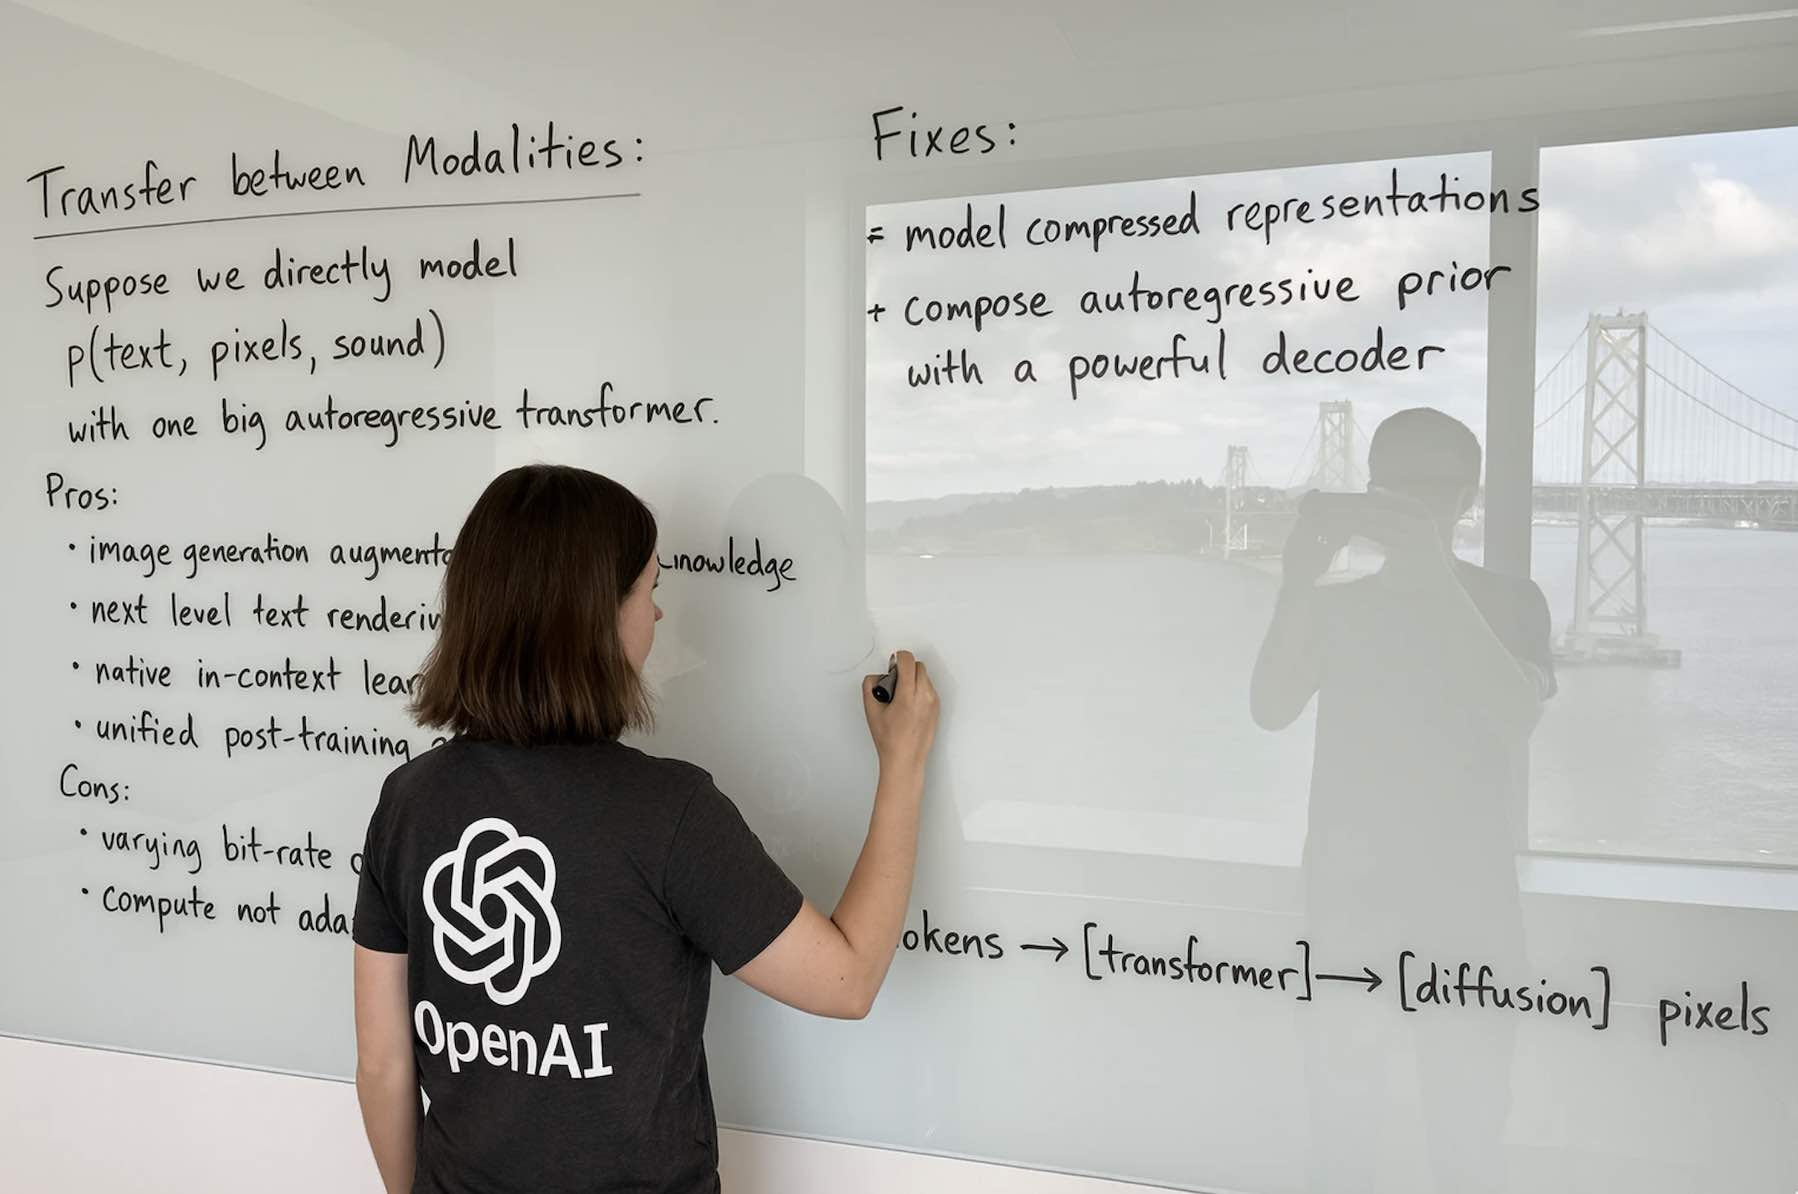

In [17]:
from IPython.display import Image, display                  # show the image in the notebook

display(Image("../images/imagetotext1.jpg", width=600))     # the photo we will ask about

In [18]:
import base64                                               # encode the image's bytes as text
from langchain_openai import ChatOpenAI                     # for Groq's OpenAI-compatible API
from langchain_openrouter import ChatOpenRouter             # for OpenRouter
from langchain.messages import HumanMessage                 # a message written by the user

with open("../images/imagetotext1.jpg", "rb") as f:         # "rb": read the raw bytes of the file
    image_base64 = base64.b64encode(f.read()).decode()      # bytes → base64 text

message = HumanMessage(content=[                            # one message, two blocks
    {"type": "text", "text": "Describe this image in three sentences."},
    {"type": "image", "base64": image_base64, "mime_type": "image/jpeg"},
])

vision_models = {
    "Groq · qwen/qwen3.8-27b": ChatOpenAI(model="qwen/qwen3.8-27b", max_tokens=400, **GROQ),
    "OpenRouter · nvidia/nemotron-3.5-super-vl:free": ChatOpenRouter(model="nvidia/nemotron-3.5-super-vl:free",
                                                                     max_tokens=2000),
}
for name in ["google/gemma-4-31b-it:free", "nvidia/nemotron-3-ultra-550b-a55b:free"]:   # a check without any call
    print(f"{name:40} image_inputs = {ChatOpenRouter(model=name).profile['image_inputs']}")
print()

for name, model in vision_models.items():                   # the same message to both
    print(f"\033[1m=== {name} ===\033[0m")
    print(model.invoke([message]).text.strip(), "\n")

google/gemma-4-31b-it:free               image_inputs = True
nvidia/nemotron-3-ultra-550b-a55b:free   image_inputs = False

=== Groq · qwen/qwen3.8-27b ===
A person wearing a black OpenAI t-shirt is standing in front of a whiteboard, writing or pointing to notes about machine learning concepts. The whiteboard contains handwritten text discussing "Transfer between Modalities" and "Fixes," including details on modeling p(text, pixels, sound) with an autoregressive transformer. A reflection in the glass window behind shows an outdoor scene with a bridge and water, as well as a silhouette of the person photographing the scene. 

=== OpenRouter · nvidia/nemotron-3.5-super-vl:free ===
A person wearing an OpenAI t-shirt stands before a whiteboard, writing notes with a marker while their reflection is visible against a backdrop of a bridge and water through a window. The board is filled with handwritten machine learning concepts under headings like "Transfer between Modalities" and "Fixes," di

## <span style='color:#7e22ce'>Example 11: Image out: OpenAI's image tool, and a local model</span>
### Step 1: With LangChain and OpenAI's `image_generation` tool (paid)
- OpenAI's `image_generation` is a **hosted tool**: we give it to `gpt-4o-mini` with `bind_tools()`, the model decides to draw, and OpenAI's image model (`gpt-image-1-mini`, low quality: the cheapest setting) does the drawing.
- The picture comes back as a standard **`image` content block**, with base64 data. (We meet tools properly in Lec-40.)

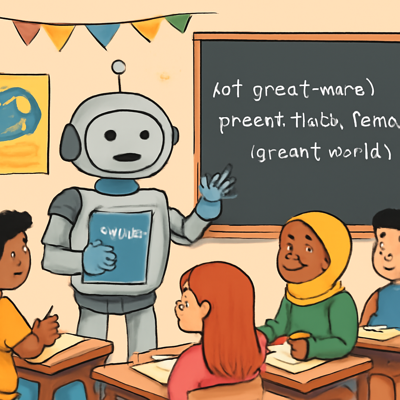

In [19]:
import io                                                   # io.BytesIO: treat bytes in memory like a file
import base64                                               # decode the picture from base64 text
from PIL import Image as PILImage                           # open and resize the picture (named to avoid IPython's Image)
from IPython.display import display                         # show the picture in the notebook
from langchain_openai import ChatOpenAI                     # LangChain class for OpenAI models

image_tool = {"type": "image_generation", "model": "gpt-image-1-mini", "quality": "low", "size": "1024x1024"}
painter = ChatOpenAI(model="gpt-4o-mini").bind_tools([image_tool])   # gpt-4o-mini may now call the drawing tool

reply = painter.invoke("Draw a simple, friendly cartoon of a robot teaching Python to students in a classroom.")
for block in reply.content_blocks:                          # the reply holds an image block (and maybe some text)
    if block["type"] == "image":
        picture = PILImage.open(io.BytesIO(base64.b64decode(block["base64"])))   # base64 → bytes → picture
        display(picture.resize((400, 400)))                 # a smaller copy in the notebook

### Step 2 (optional): A free model on your laptop, without LangChain
- `stabilityai/sd-turbo` is a small open text-to-image model that runs on a CPU through Hugging Face's `diffusers` library (not LangChain). The first run downloads it.
- **SD-Turbo** was trained to draw in **1 to 4 steps** with **no guidance** (`guidance_scale=0.0`): more steps or a higher guidance scale make its pictures worse, not better.

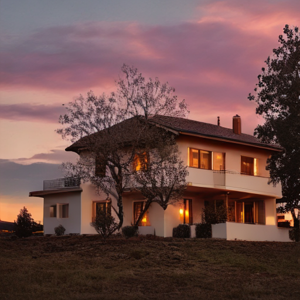

In [20]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"            # no download progress bars in the saved output
import warnings                                             # hide library warnings we expect
warnings.filterwarnings("ignore")
import torch                                                # PyTorch, which runs the model
from transformers.utils import logging as transformers_logging   # transformers' own messages (diffusers uses it)
transformers_logging.set_verbosity_error()                  # print only errors
from diffusers import AutoPipelineForText2Image             # Hugging Face's text-to-image pipelines
from diffusers.utils import logging as diffusers_logging    # diffusers' own messages
from IPython.display import display                         # show the picture in the notebook

diffusers_logging.set_verbosity_error()                     # print only errors
diffusers_logging.disable_progress_bar()                    # and no progress bars

pipe = AutoPipelineForText2Image.from_pretrained("stabilityai/sd-turbo", dtype=torch.float32).to("cpu")   # float32 for CPU
pipe.set_progress_bar_config(disable=True)                  # no progress bar while it draws

image = pipe(prompt="A house at sunset, with trees and mountains in the background",
             num_inference_steps=1,                         # SD-Turbo: 1 to 4 steps
             guidance_scale=0.0).images[0]                  # SD-Turbo: no classifier-free guidance
display(image.resize((300, 300)))

# <span style='background :lightgreen' >8. Hands-On Practice</span>

A small helper, `ask()`, keeps the practice examples short. It works with any LangChain chat model: by default Groq's `gpt-oss-120b`, or `"openrouter"` for a free OpenRouter model with backups.

In [21]:
from langchain_openrouter import ChatOpenRouter             # LangChain's class for OpenRouter
from langchain.messages import SystemMessage, HumanMessage  # the instructions and the user's message

OPENROUTER_FREE = ChatOpenRouter(model="nvidia/nemotron-3-ultra-550b-a55b:free", max_tokens=2000,   # free, with a backup
                                 model_kwargs={"models": ["nvidia/nemotron-3.5-super-vl:free"]})
CHAT_MODELS = {"groq": GROQ_MODEL, "openrouter": OPENROUTER_FREE}   # GROQ_MODEL comes from Example 3

def ask(user_prompt, system_prompt="You are a helpful assistant that provides concise answers.",
        model="groq", temperature=None, stream=False):
    '''Send one question to a chat model; return the answer's text (or a stream of chunks).'''
    chat_model = CHAT_MODELS[model]
    if temperature is not None:
        chat_model = chat_model.bind(temperature=temperature)   # .bind(): the same model with one setting changed
    messages = [SystemMessage(system_prompt), HumanMessage(user_prompt)]   # the same messages for every provider
    if stream:
        return chat_model.stream(messages)                  # the caller loops over the chunks
    return chat_model.invoke(messages).text                 # only the text of the answer

## a. Question answering

In [22]:
print(ask("Which is the capital of Pakistan?"))

Islamabad.


In [23]:
print(ask("Who is Imran Khan? Answer in three sentences.", model="openrouter"))   # the same helper, a free OpenRouter model

Imran Khan is a former international cricketer who captained Pakistan to its only Cricket World Cup victory in 1992. He transitioned into politics, founding the Pakistan Tehreek-e-Insaf (PTI) party in 1996 and serving as the country's 22nd Prime Minister from 2018 until his removal via a no-confidence vote in 2022. Since his ouster, he has faced numerous legal challenges and imprisonment, remaining a polarizing figure in Pakistani politics.


## b. Question answering from the content we pass

In [24]:
with open("../data/names.txt", "r") as f:                   # a text file with a few names
    file_content = f.read()

print(ask(f"Extract the names of the cricket players from this text:\n{file_content}"))

Imran Khan  
Wasim Akram  
Shahid Afridi  
Babar Azam  
Shaheen Shah Afridi  
Shadab Khan


## c. Binary classification (sentiment analysis, spam detection, …)

In [25]:
system_prompt = "Classify the sentiment of the sentence as either Positive or Negative. Reply with one word."
print(ask("I love the YouTube videos of Arif, as they are very informative.", system_prompt))

Positive


## d. Multi-class classification

In [26]:
system_prompt = ("Classify product reviews into these categories: 'Electronics', 'Clothing', 'Books', "
                 "'Home & Garden', 'Sports', or 'Food'. Respond with only the category.")
print(ask("This novel has an incredible plot twist that kept me reading all night.", system_prompt))

Books


## e. Classifying many reviews at once with `batch()`
The same instructions for five reviews, sent together (Example 8).

In [27]:
from langchain.messages import SystemMessage, HumanMessage  # the instructions and the user's message

reviews = ["The running shoes fell apart after one week of jogging.",
           "Fresh mangoes, very sweet, delivered on time.",
           "The earphones stopped charging after a month.",
           "This cotton shirt shrank after the first wash.",
           "A great introduction to machine learning; the examples are clear."]

conversations = [[SystemMessage(system_prompt), HumanMessage(review)] for review in reviews]   # one list of messages each
for review, reply in zip(reviews, GROQ_MODEL.batch(conversations)):   # system_prompt is the one of section d
    print(f"{reply.text:12} ← {review}")

Sports       ← The running shoes fell apart after one week of jogging.
Food         ← Fresh mangoes, very sweet, delivered on time.
Electronics  ← The earphones stopped charging after a month.
Clothing     ← This cotton shirt shrank after the first wash.
Books        ← A great introduction to machine learning; the examples are clear.


## f. Text generation

In [28]:
system_prompt = "You are an expert in political science and history, with a deep understanding of Pakistan's politics."
print(ask("Write a 50-word summary about the fairness of the general elections held in Pakistan on February 8, 2024.",
          system_prompt, temperature=1.5))                  # a high temperature: more varied wording

International observers noted improvements, but irregularities persisted, casting doubt on the February 8, 2024 Pakistani general election's fairness. While voter turnout rose and major parties competed openly, reports of ballot‑stuffing, intimidation, and delayed results in several constituencies fueled criticism, suggesting only partial compliance with standards and require reform measures now.


## g. Code generation (streamed)

In [29]:
for chunk in ask("Write a C program that prints the first ten numbers of the Fibonacci sequence.",
                 "You are an expert C programmer.", stream=True):
    print(chunk.text, end="", flush=True)                   # print each piece as it arrives

Here is a simple, self‑contained C program that prints the first ten numbers of the Fibonacci sequence (starting with 0, 1).  
It uses an iterative loop, which is the most straightforward and efficient way for this small task.

```c
/*  fibonacci.c
 *
 *  Prints the first ten numbers of the Fibonacci sequence:
 *  0 1 1 2 3 5 8 13 21 34
 *
 *  Compile with: gcc -Wall -Wextra -o fibonacci fibonacci.c
 */

#include <stdio.h>

int main(void)
{
    const int N = 10;          /* how many terms to print */
    unsigned long fib0 = 0;    /* first term  */
    unsigned long fib1 = 1;    /* second term */

    printf("%d Fibonacci numbers:\n", N);

    for (int i = 0; i < N; ++i)
    {
        if (i == 0)
            printf("%lu", fib0);          /* print 0 */
        else if (i == 1)
            printf(" %lu", fib1);          /* print 1 */
        else
        {
            unsigned long next = fib0 + fib1;  /* compute next term */
            printf(" %lu", next);
            fib0 = fib1;    

## h. Translation

In [30]:
system_prompt = "You are an expert English-to-Urdu translator. Translate the user's text into Urdu."
print(ask("The budget this year will have a very bad impact on low-salaried people.", system_prompt))

اس سال کا بجٹ کم آمدنی والے افراد پر بہت منفی اثر ڈالے گا۔


## i. Summarisation

In [31]:
bio_text = '''
Dr. Muhammad Arif Butt is an accomplished Assistant Professor at the Department of Data Science, University of the Punjab (PU), Lahore, Pakistan.
He holds an MSc and MPhil (both with Gold Medals) and a Ph.D. in Computer Science from PUCIT, University of the Punjab. His research focuses on fuzzy
inference models applied to operating systems, embedded systems, and cloud-based services, particularly in decision-making under uncertain and
imprecise conditions. With over 33 years of experience in teaching and management, Dr. Butt has served in both the Pakistan Army and University
of the Punjab, bringing a wealth of interdisciplinary expertise. His teaching specializations include embedded and real-time operating systems, system programming,
cybersecurity, and artificial intelligence. Beyond academia, he is a technology entrepreneur, serving as the Founder of Excaliat and Falcon-Hunt and Co-Founder of Tbox Solutionz.
In recent years, he has gained significant expertise in vulnerability research, binary exploitation, and exploit development, excelling in identifying and mitigating critical security risks
across diverse platforms. His deep understanding of software architectures, memory corruption techniques, and attack vectors strengthens his ability to proactively enhance cybersecurity defences.
A dedicated and results-driven professional, Dr. Butt is recognized for his strong organizational skills, strategic thinking, and ability to thrive in collaborative environments.
His expertise in cybersecurity and emerging technologies enables him to contribute effectively to both academic research and industry innovation, reinforcing defences against evolving cyber threats.
'''

print(ask(f"Summarize the text below in at most 50 words:\n\n{bio_text}", "You are an expert of the English language.",
          model="openrouter"))                              # a free OpenRouter model

Dr. Muhammad Arif Butt, Assistant Professor at Punjab University, holds a Ph.D. and Gold Medals. With 33+ years' military and academic experience, he researches fuzzy inference models and teaches embedded systems, AI, and cybersecurity. A tech entrepreneur, he specializes in vulnerability research and binary exploitation, bridging academic theory and industry practice to strengthen cyber defenses.


## j. Named entity recognition

In [32]:
system_prompt = '''You are a named entity recognition specialist. Extract and classify the entities of the text into these
categories, only if they exist: name, major, university, nationality, grades, club.
Format each entity on its own line as: Entity: [text] | Type: [category]'''

user_prompt = '''Zelaid Mujahid is a sophomore majoring in Data Science at the University of the Punjab.
He is a Pakistani national and has a 3.5 GPA. Mujahid is an active member of the department's AI Club.
He hopes to pursue a career in AI after graduating.'''

print(ask(user_prompt, system_prompt))

Entity: Zelaid Mujahid | Type: name  
Entity: Data Science | Type: major  
Entity: University of the Punjab | Type: university  
Entity: Pakistani | Type: nationality  
Entity: 3.5 GPA | Type: grades  
Entity: AI Club | Type: club


# <span style='background :lightgreen' >9. Embedding Models</span>

<div style="text-align:center;">
    <img src="../images/langchain-new-10.png"
         style="max-width:1500px; width:100%; height:auto; display:inline-block;">
</div>

- An embedding model turns a text into a **vector**: a list of a few hundred or a few thousand numbers. Texts with similar meaning get vectors that point in similar directions.
- **Cosine similarity** measures how close two directions are: near 1 for the same meaning, near 0 for unrelated texts.
- Every embedding class has the same two methods: `embed_documents(list_of_texts)` and `embed_query(text)`.

| Provider | Model | Runs | Numbers per vector |
|---|---|---|---|
| OpenAI | `text-embedding-3-small` | API (paid) | 1536 |
| OpenAI | `text-embedding-3-large` | API (paid) | 3072 |
| Google | `gemini-embedding-001` | API (free tier) | 3072 |
| OpenRouter | `nvidia/nemotron-3.5-embed-1b:free` | API (free) | 2048 |
| Ollama | `nomic-embed-text` | Your laptop | 768 |
| Hugging Face | `sentence-transformers/all-MiniLM-L6-v2` | Your laptop | 384 |

The helper below embeds three short documents and a question, and prints how close each document is to the question. We then call it with three different embedding models: only the embedding object changes.

In [33]:
import numpy as np                                          # vectors and dot products

DOCUMENTS = ["Islamabad is the capital of Pakistan",       # a tiny "knowledge base"
             "Paris is the capital of France",
             "Rome is the capital of Italy"]
QUERY = "What is the capital of Pakistan?"                  # the question we search with

def cosine_similarity(a, b):
    '''cos θ = (a · b) / (|a| |b|): 1 = same direction, 0 = unrelated.'''
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def compare(embedder):
    '''Embed the documents and the query with any LangChain embedding model, and rank the documents.'''
    doc_vectors = embedder.embed_documents(DOCUMENTS)       # a LIST of texts → a list of vectors (one call)
    query_vector = embedder.embed_query(QUERY)              # ONE text → one vector
    print("Numbers per vector:", len(query_vector))
    scores = [cosine_similarity(query_vector, v) for v in doc_vectors]
    for doc, score in zip(DOCUMENTS, scores):
        print(f"   {score:.4f}  {doc}")
    print("Best match:", DOCUMENTS[int(np.argmax(scores))])  # argmax: the position of the highest score

## <span style='color:#7e22ce'>Example 12: A closed-source embedding model (OpenAI)</span>
`OpenAIEmbeddings` reads `OPENAI_API_KEY` by itself. (`dimensions=256` would shorten the vectors, to save memory.)

In [34]:
from langchain_openai import OpenAIEmbeddings               # LangChain class for OpenAI's embedding models

compare(OpenAIEmbeddings(model="text-embedding-3-small"))   # paid, but these few words cost a tiny fraction of a cent

Numbers per vector: 1536
   0.7630  Islamabad is the capital of Pakistan
   0.4174  Paris is the capital of France
   0.2285  Rome is the capital of Italy
Best match: Islamabad is the capital of Pakistan


## <span style='color:#7e22ce'>Example 13: An open-source embedding model through an API (OpenRouter, free)</span>
OpenRouter's embeddings API is OpenAI-compatible, so `OpenAIEmbeddings` works with OpenRouter's URL. `check_embedding_ctx_length=False` is needed for every non-OpenAI model: otherwise LangChain first splits the text with OpenAI's own tokenizer and sends token numbers that other models do not understand.

In [35]:
import os                                                   # read OPENROUTER_API_KEY
from langchain_openai import OpenAIEmbeddings               # works with any OpenAI-compatible embeddings API

compare(OpenAIEmbeddings(model="nvidia/nemotron-3.5-embed-1b:free",   # a free embedding model
                         base_url="https://openrouter.ai/api/v1", api_key=os.getenv("OPENROUTER_API_KEY"),
                         check_embedding_ctx_length=False))   # send plain text, not OpenAI token numbers

Numbers per vector: 2048
   0.8433  Islamabad is the capital of Pakistan
   0.4248  Paris is the capital of France
   0.3594  Rome is the capital of Italy
Best match: Islamabad is the capital of Pakistan


## <span style='color:#7e22ce'>Example 14: An open-source embedding model on your laptop (Hugging Face)</span>
`HuggingFaceEmbeddings` downloads the model once and runs it on your computer: free, offline and private. These are the numbers shown in the figure above.

In [36]:
import os
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"            # no download progress bars in the saved output
from transformers.utils import logging as transformers_logging   # transformers' own messages
transformers_logging.disable_progress_bar()                 # no "Loading weights" bar
from langchain_huggingface import HuggingFaceEmbeddings     # LangChain class for local Hugging Face models

compare(HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2"))   # 384 numbers per text

Numbers per vector: 384
   0.8102  Islamabad is the capital of Pakistan
   0.2054  Paris is the capital of France
   0.3416  Rome is the capital of Italy
Best match: Islamabad is the capital of Pakistan


# <span style='background :lightgreen' >10. Summary: From Provider SDKs → LangChain</span>

| What we did with each provider's SDK (Lec-01 to 08) | With LangChain |
|---|---|
| A different client class per provider | One class per provider (`ChatOpenAI`, `ChatAnthropic`, …), or `init_chat_model("provider:model")` |
| `client.chat.completions.create(...)`, `client.messages.create(...)`, … | `model.invoke(messages)` for every provider |
| `response.choices[0].message.content`, `response.content[0].text`, … | `response.text` (and `response.content_blocks`) |
| `stream=True` and provider-specific chunks | `model.stream(messages)` |
| A loop of calls | `model.batch([...])` |
| Asking for JSON and parsing it ourselves | `model.with_structured_output(PydanticClass)` |
| Groq, OpenRouter, Ollama through a `base_url` (Lec-07, 08) | The same `base_url` trick with `ChatOpenAI`, or `ChatOpenRouter` and `ChatOllama` |
| A different embeddings call per provider | `embed_documents()` and `embed_query()` for every embedding model |

### Key takeaways
- **LangChain** puts one standard interface in front of every model provider. **Integration packages** translate each call into the provider's own API.
- LangChain is a **family of packages**: `langchain-core` (the interfaces), one package per provider, and `langchain`, `langgraph` and `deepagents` for agents.
- The Models component has **chat models** (messages in, an `AIMessage` out), legacy **text-completion** models, and **embedding models** (text in, a vector out).
- There are three ways to create a chat model: a **provider class**, **`init_chat_model("provider:model")`**, or **`ChatOpenAI` with an OpenAI-compatible `base_url`**, which works everywhere but loses the profile and the reasoning text.
- A model **remembers nothing**: a conversation is a list of messages that we send again on every call.
- `invoke()` waits for the whole answer, `stream()` delivers it piece by piece, and `batch()` answers many independent inputs at the same time.
- **Structured output** turns the answer into a validated Python object that a program can use directly.
- Free **reasoning** models need a generous `max_tokens`, and free OpenRouter models need a **fallback list**.
- **Next lecture (Lec-31):** the **Prompts** component: reusable prompt templates.

### Check your understanding
1. Name three things that differ between the OpenAI SDK and the Anthropic SDK, and what replaces each in LangChain.
2. What is in `langchain-core`, and what is in an integration package such as `langchain-openai`?
3. What does `init_chat_model("ollama:llama3.2:1b")` return? How does it know which class to create?
4. Why does `ChatOpenAI` work with Groq? What do we lose compared with a dedicated package, and why did we not use `langchain-groq`?
5. In Example 4, why was the answer empty with `max_tokens=60`? How could you tell, although no error was raised?
6. What does the `"models"` list of `ChatOpenRouter` do? How do you find out which model answered?
7. In Example 6, which parts of the `AIMessage` would you use to (a) show the answer, (b) count the cost, (c) check that the answer was not cut off?
8. Why could the model not answer "What's my favourite programming language?" in Step 1 of Example 7? What did Step 2 change?
9. When would you use `stream()`, and when `batch()`? Why was `batch()` faster than the `for` loop in Example 8?
10. What does `with_structured_output(Review)` return, and why is `Literal["positive", "negative", "mixed"]` useful?
11. How is an image put into a message? How can you check, without a call, whether a model can read images?
12. What do `embed_documents()` and `embed_query()` return? Why did "Islamabad is the capital of Pakistan" win in all three embedding examples, although the vectors had different lengths?